## 📓 Notebook 06: Final Comparison

**Skills practiced:** Assembling results into one DataFrame, overlaying plots from multiple models.

**Goal:** Produce one table (library, training time, ROC-AUC, best hyperparameters, native categorical handling) and one overlaid loss-curve plot for all three libraries.

In [18]:
import matplotlib.pyplot as plt
from matplotlib import patheffects as pe
import joblib

In [19]:
xgb=joblib.load('../models/xgb_model.joblib')
lgb=joblib.load('../models/lgb_model.joblib')
cb=joblib.load('../models/cb_model.joblib')

|  Library  | Training time (s) | Validation ROC-AUC | Manual encoding needed |
|-----------|-------------------|--------------------|------------------------|
|  XGBoost  | 04.45             | 0.8321             | Yes                    |
|  LightGBM | 01.15             | 0.8183             | Yes                    |
|  CatBoost | 12.72             | 0.8452             | No                     |

In [20]:
def get_losses(name, model):
    if name == "xgb":
        res = model.evals_result()
        return res["validation_0"]["logloss"], res["validation_1"]["logloss"]
    if name == "lgb":
        res = model.evals_result_
        keys = list(res.keys())
        return res[keys[0]]["binary_logloss"], res[keys[1]]["binary_logloss"]
    if name == "cb":
        res = model.get_evals_result()
        keys = list(res.keys())
        return res[keys[0]]["Logloss"], res[keys[1]]["Logloss"]

model_dict = {"xgb": xgb, "lgb": lgb, "cb": cb}   # fitted models
train_loss, val_loss = {}, {}

for name, model in model_dict.items():
    train_loss[name], val_loss[name] = get_losses(name, model)

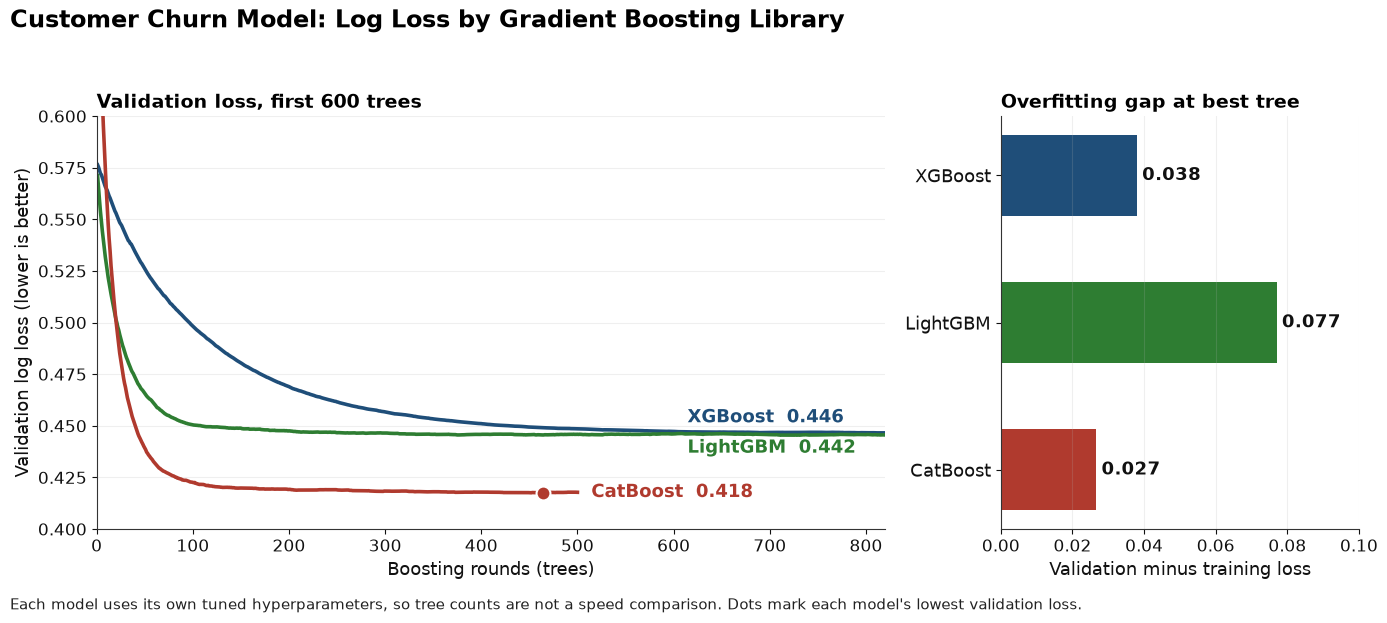

In [21]:

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#111111",
    "xtick.color": "#111111",
    "ytick.color": "#111111",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

colors = {"XGBoost": "#1f4e79", "LightGBM": "#2e7d32", "CatBoost": "#b03a2e"}
curves = {
    "XGBoost":  (train_loss["xgb"], val_loss["xgb"]),
    "LightGBM": (train_loss["lgb"], val_loss["lgb"]),
    "CatBoost": (train_loss["cb"],  val_loss["cb"]),
}
label_dy = {"XGBoost": 10, "LightGBM": -10, "CatBoost": 0}

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2.2, 1]}
)

gaps = {}
for name, (train, val) in curves.items():
    c = colors[name]
    best = val.index(min(val)) + 1
    ax1.plot(range(1, len(val) + 1), val, color=c, linewidth=2.6)
    ax1.scatter(best, min(val), color=c, edgecolor="white", linewidth=1.5, s=100, zorder=4)

    end_x = min(len(val), 600)
    txt = ax1.annotate(f"{name}  {min(val):.3f}", xy=(end_x, val[end_x - 1]),
                       xytext=(10, label_dy[name]), textcoords="offset points",
                       color=c, fontsize=13, fontweight="bold", va="center")
    # white outline keeps text readable where it crosses gridlines or lines
    txt.set_path_effects([pe.withStroke(linewidth=3, foreground="white")])

    gaps[name] = val[best - 1] - train[best - 1]

ax1.set_xlim(0, 820)
ax1.set_ylim(0.40, 0.60)
ax1.set_xlabel("Boosting rounds (trees)", fontsize=13)
ax1.set_ylabel("Validation log loss (lower is better)", fontsize=13)
ax1.set_title("Validation loss, first 600 trees", fontsize=14, fontweight="bold", loc="left")

names = list(gaps)
bars = ax2.barh(names, [gaps[n] for n in names], color=[colors[n] for n in names], height=0.55)
for bar, n in zip(bars, names):
    ax2.text(bar.get_width() + 0.0015, bar.get_y() + bar.get_height() / 2,
             f"{gaps[n]:.3f}", va="center", fontsize=13, fontweight="bold", color="#111111")
ax2.set_xlim(0, max(gaps.values()) * 1.3)
ax2.invert_yaxis()
ax2.set_xlabel("Validation minus training loss", fontsize=13)
ax2.set_title("Overfitting gap at best tree", fontsize=14, fontweight="bold", loc="left")
ax2.tick_params(axis="y", labelsize=13)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, axis="y" if ax is ax1 else "x", alpha=0.2)

fig.suptitle("Customer Churn Model: Log Loss by Gradient Boosting Library",
             fontsize=17, fontweight="bold", x=0.01, ha="left")
fig.text(0.01, -0.02,
         "Each model uses its own tuned hyperparameters, so tree counts are not a speed comparison. "
         "Dots mark each model's lowest validation loss.",
         fontsize=11, color="#222222", ha="left")

fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("../outputs/figures/all_libraries_loss.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()